In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

all_data = pd.concat([train, test], ignore_index=True)


In [3]:
all_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             2919 non-null   int64  
 1   MSSubClass     2919 non-null   int64  
 2   MSZoning       2915 non-null   object 
 3   LotFrontage    2433 non-null   float64
 4   LotArea        2919 non-null   int64  
 5   Street         2919 non-null   object 
 6   Alley          198 non-null    object 
 7   LotShape       2919 non-null   object 
 8   LandContour    2919 non-null   object 
 9   Utilities      2917 non-null   object 
 10  LotConfig      2919 non-null   object 
 11  LandSlope      2919 non-null   object 
 12  Neighborhood   2919 non-null   object 
 13  Condition1     2919 non-null   object 
 14  Condition2     2919 non-null   object 
 15  BldgType       2919 non-null   object 
 16  HouseStyle     2919 non-null   object 
 17  OverallQual    2919 non-null   int64  
 18  OverallC

In [4]:
null_counts = all_data.isnull().sum()
null_pct = (null_counts/len(all_data))*100
null_df = pd.DataFrame({'Count':null_counts,'Percent':null_pct})
null_df = null_df[null_df['Count']>0].sort_values(by='Percent', ascending=False)
null_df

,Count,Percent
PoolQC,2909,99.657417
MiscFeature,2814,96.402878
Alley,2721,93.216855
Fence,2348,80.438506
MasVnrType,1766,60.500171
SalePrice,1459,49.982871
FireplaceQu,1420,48.646797
LotFrontage,486,16.649538
GarageQual,159,5.447071
GarageYrBlt,159,5.447071


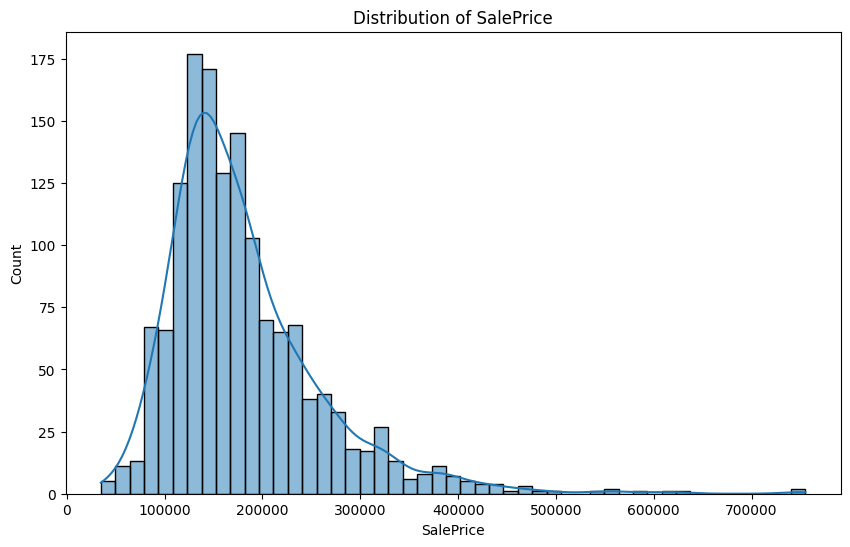

In [5]:
from scipy.stats import skew

plt.figure(figsize=(10,6))
sns.histplot(train['SalePrice'],kde=True)
plt.title('Distribution of SalePrice')
plt.show()

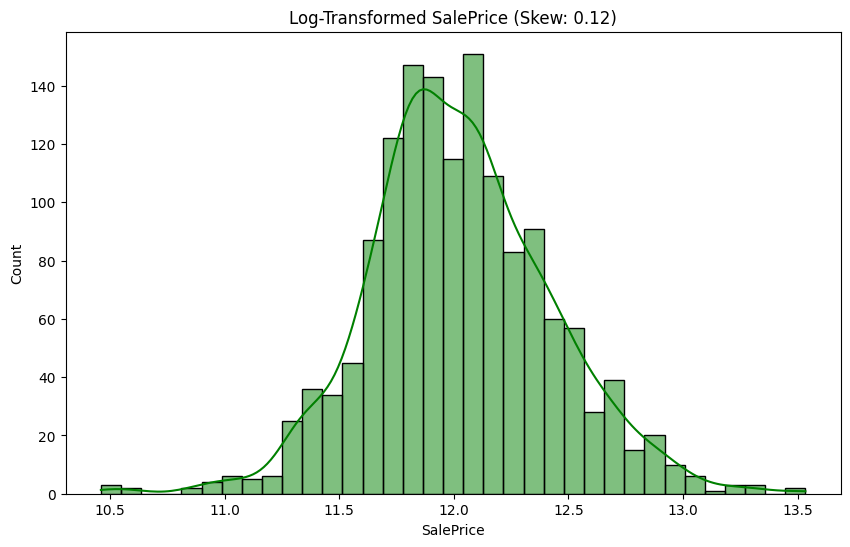

In [6]:
train['SalePrice'] = np.log1p(train['SalePrice'])

plt.figure(figsize=(10,6))
sns.histplot(train['SalePrice'], kde=True, color='green')
plt.title(f"Log-Transformed SalePrice (Skew: {train['SalePrice'].skew():.2f})")
plt.show()

In [7]:
corr = train.select_dtypes(include=[np.number]).corr()
corr['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.817185
GrLivArea        0.700927
GarageCars       0.680625
GarageArea       0.650888
TotalBsmtSF      0.612134
1stFlrSF         0.596981
FullBath         0.594771
YearBuilt        0.586570
YearRemodAdd     0.565608
GarageYrBlt      0.541073
TotRmsAbvGrd     0.534422
Fireplaces       0.489450
MasVnrArea       0.430809
BsmtFinSF1       0.372023
LotFrontage      0.355879
WoodDeckSF       0.334135
OpenPorchSF      0.321053
2ndFlrSF         0.319300
HalfBath         0.313982
LotArea          0.257320
BsmtFullBath     0.236224
BsmtUnfSF        0.221985
BedroomAbvGr     0.209043
ScreenPorch      0.121208
PoolArea         0.069798
MoSold           0.057330
3SsnPorch        0.054900
BsmtFinSF2       0.004832
BsmtHalfBath    -0.005149
Id              -0.017942
MiscVal         -0.020021
OverallCond     -0.036868
YrSold          -0.037263
LowQualFinSF    -0.037963
MSSubClass      -0.073959
KitchenAbvGr    -0.147548
EnclosedPorch   -0.149050
Name: SalePr

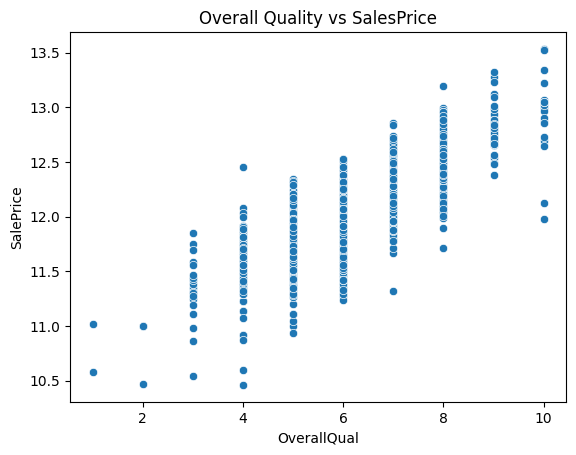

In [8]:
sns.scatterplot(x = train['OverallQual'], y= train['SalePrice'])
plt.title('Overall Quality vs SalesPrice')
plt.show()

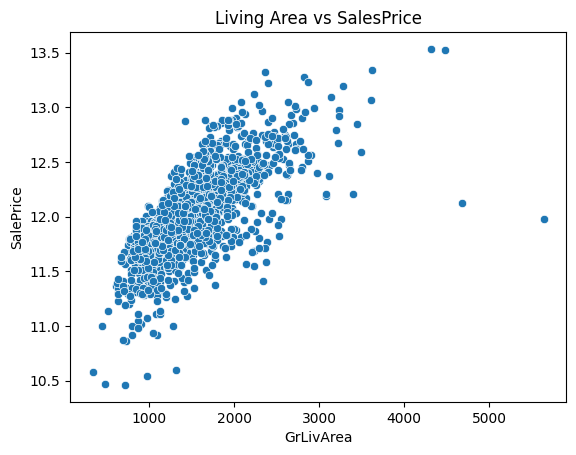

In [9]:
sns.scatterplot(x = train['GrLivArea'], y= train['SalePrice'])
plt.title('Living Area vs SalesPrice')
plt.show()

In [ ]:

train_test = train.copy()
train_test['TotalSF'] = train_test['TotalBsmtSF'] + train_test['1stFlrSF'] + train_test['2ndFlrSF']
train_test['Qual_SF'] = train_test['OverallQual'] * train_test['TotalSF']


corr_sf = train_test['SalePrice'].corr(train_test['TotalSF'])
corr_qual_sf = train_test['SalePrice'].corr(train_test['Qual_SF'])

print(f"TotalSF Correlation: {corr_sf:.4f}")
print(f" Qual_SF Correlation: {corr_qual_sf:.4f}")

TotalSF Correlation: 0.7773
 Qual_SF Correlation: 0.8248
